# Neural Networks in PyTorch - Example on MNIST Handwritten Digit Classification

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms

# Set random seed for reproducibility
torch.manual_seed(302)
np.random.seed(302)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)) # this ensures that the mean pixel value is 0 and the standard deviation is 1
])

train_dataset = datasets.MNIST('./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST('./data', train=False, transform=transform)

print(train_dataset); print(test_dataset)

# Creating data loaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=True)


100.0%
100.0%
100.0%
100.0%

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.1307,), std=(0.3081,))
           )
Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.1307,), std=(0.3081,))
           )


## Explorative Data Analysis

tensor([4, 9, 1, 1, 6, 9, 4, 6, 1])


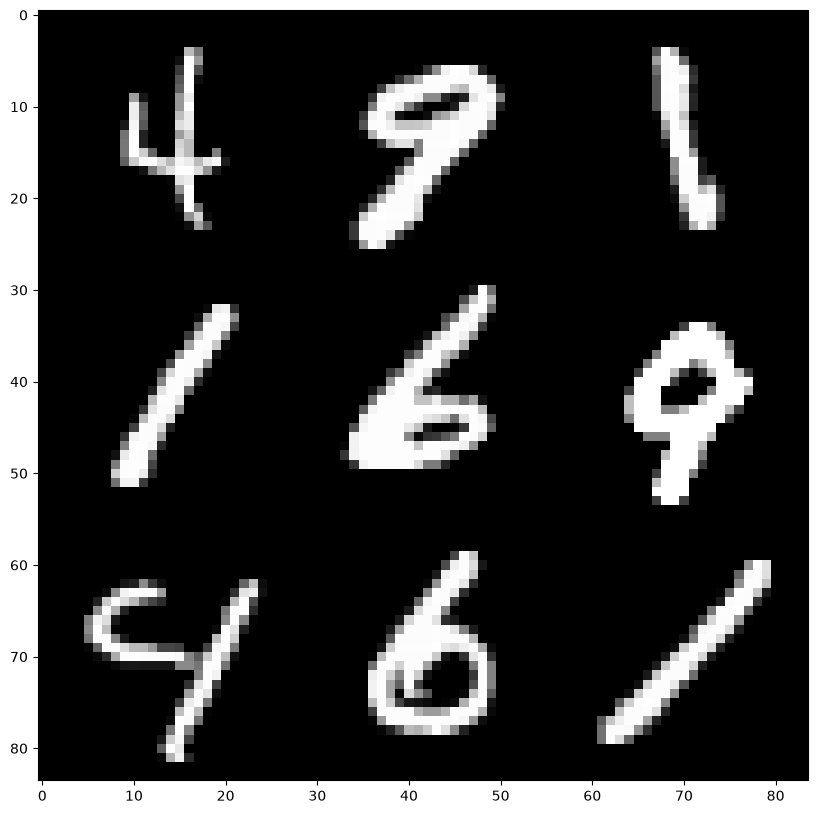

In [9]:
from matplotlib import pyplot as plt

image_batch, label_batch = next(iter(train_loader))
image_batch.shape, label_batch.shape

print(label_batch[:9])

plt.figure(figsize=(10, 10))
plt.imshow(image_batch[:9, 0, :, :]
           .reshape(3, 3, 28, 28)
           .permute(0, 2, 1, 3)
           .reshape(28*3, 28*3), cmap='gray')
plt.show()

## Defining the Network

Feed-forward neural network with 3 hidden layers in PyTorch:

In [3]:
class NeuralNet(nn.Module):
    def __init__(self):
      super(NeuralNet, self).__init__()
      self.fc1 = nn.Linear(in_features=28*28, out_features=128)
      self.fc2 = nn.Linear(in_features=128, out_features=128)
      self.fc3 = nn.Linear(in_features=128, out_features=10)


    def forward(self, x):
      # Flatten the data (B, 1, 28, 28) => (B, 784), where B is the batch size
      x = torch.flatten(x, start_dim=1)

      # Pass data through 1st fully connected layer
      x = self.fc1(x)
      # Apply ReLU non-linearity
      x = F.relu(x)

      # Pass data through 2nd fully connected layer
      x = self.fc2(x)
      # Apply ReLU non-linearity
      x = F.relu(x)

      # Pass data through 3rd fully connected layer
      x = self.fc3(x)

      # The output values in x are called logits
      return x

In [10]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = NeuralNet().to(device)
print(model)

# Parameters of the model
for p in model.parameters():
    print(p.shape)

NeuralNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)
torch.Size([128, 784])
torch.Size([128])
torch.Size([128, 128])
torch.Size([128])
torch.Size([10, 128])
torch.Size([10])


In [12]:
# Just looking into how the inputs and (untrained) model outputs would look like
x = image_batch[:1].to(device)
print(f'Input image shape: {x.shape}')

outputs = model(x)
print(f'Model output logits: {outputs}')

probs = F.softmax(outputs, dim=1)
print(f'Model output probabilities: {probs}')

Input image shape: torch.Size([1, 1, 28, 28])
Model output logits: tensor([[ 0.1477,  0.0432, -0.0433,  0.0732,  0.0473, -0.0507,  0.0319, -0.0096,
          0.1129, -0.0288]], device='cuda:0', grad_fn=<AddmmBackward0>)
Model output probabilities: tensor([[0.1120, 0.1009, 0.0925, 0.1040, 0.1013, 0.0918, 0.0998, 0.0957, 0.1082,
         0.0939]], device='cuda:0', grad_fn=<SoftmaxBackward0>)


## Training the model

In [ ]:
learning_rate = 0.01
num_epochs = 5

model = NeuralNet().to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
loss_fn = nn.CrossEntropyLoss()

losses = []
for epoch in range(num_epochs):
    print('-'*20, f'Epoch {epoch}', '-'*20)
    # Train one epoch
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)

        optimizer.zero_grad()
        outputs = model(data)
        loss = loss_fn(outputs, target)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        if batch_idx % 100 == 0:
            print(f'Train Epoch {epoch} | Loss: {loss.item()}')
    print(f'\nAverage train loss in epoch {epoch}: {np.mean(losses[-len(train_loader):])}')

    # Evaluate on test set (for monitoring training at the end of each epoch
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            outputs = model(data)
            test_loss += loss_fn(outputs, target).item()
            probs = F.softmax(outputs, dim=1)
            pred = torch.argmax(probs, dim=1)  # get the index of the max probability as the predicted output
            correct += (pred == target).sum().item()

    test_loss = test_loss / len(test_loader)
    avg_correct = correct / len(test_loader.dataset)
    print(f'Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(test_loader.dataset)} ({100. * avg_correct:.0f}%)\n')

-------------------- Epoch 0 --------------------
Train Epoch 0 | Loss: 2.3038687705993652
Train Epoch 0 | Loss: 2.030884027481079
Train Epoch 0 | Loss: 1.0827739238739014
Train Epoch 0 | Loss: 0.703984797000885
Train Epoch 0 | Loss: 0.5577473044395447
Train Epoch 0 | Loss: 0.5653090476989746
Train Epoch 0 | Loss: 0.40799790620803833
Train Epoch 0 | Loss: 0.42706120014190674
Train Epoch 0 | Loss: 0.33972662687301636
Train Epoch 0 | Loss: 0.28344786167144775

Average train loss in epoch 0: 0.8204094512122018
Test set: Average loss: 0.3352, Accuracy: 9029/10000 (90%)

-------------------- Epoch 1 --------------------
Train Epoch 1 | Loss: 0.4031665325164795
Train Epoch 1 | Loss: 0.18516001105308533
Train Epoch 1 | Loss: 0.2747381329536438
Train Epoch 1 | Loss: 0.3222253918647766
Train Epoch 1 | Loss: 0.31100907921791077
Train Epoch 1 | Loss: 0.28678303956985474
Train Epoch 1 | Loss: 0.5143954157829285
Train Epoch 1 | Loss: 0.2318955361843109
Train Epoch 1 | Loss: 0.2859737277030945
Train

## Plot Loss Curve

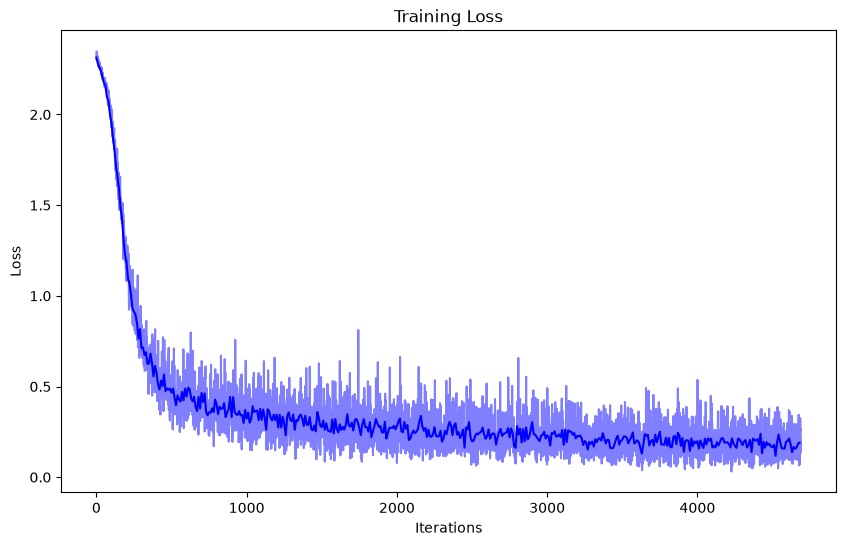

In [8]:
losses_smoothed = np.array(losses).reshape(-1, 10).mean(axis=1) # average every 10 batch losses
steps = np.arange(len(losses))

plt.figure(figsize=(10, 6))
plt.plot(steps, losses, 'b', alpha=0.5)
plt.plot(steps[::10], losses_smoothed, 'b')
plt.title('Training Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.show()